# Load data

In [7]:
import numpy as np
import pandas as pd
import torch
from sklearn import preprocessing
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN, HDBSCAN, AgglomerativeClustering
from sklearn.metrics import homogeneity_score
from sklearn.decomposition import PCA

In [8]:
# Load the file using the path exactly as it was saved
# file_path = '../data/embeddings/embeddings_171225_2176_32768_blocks.28.mlp.l3.pt' 
file_path = '../data/embeddings/embeddings_2026-1-27_12-28-7_2176_32768_blocks.28.mlp.l3_16384_0_0.pt'
# file_path = 'embeddings_291225_2176_32768_blocks.28.mlp.l3_32768.pt'
data = torch.load(file_path, map_location=torch.device('cpu'))

# Extract the lists from the dictionary
ids = data["ids"]               # List of strings
# DeepPL files contains accession id without version number, so we need to erase it from our ids
ids = [item.split('.')[0] for item in ids] 
embeddings_list = data["embeddings"] # List of torch.Tensors

# Stack the list of tensors into one large tensor (N_samples x 4096)
embeddings_tensor = torch.stack(embeddings_list)

# Convert to Numpy array
loaded_embeds = embeddings_tensor.detach().cpu().numpy()
loaded_ids = np.array(ids)

print("Embeddings shape:", loaded_ids.shape)
print("Embeddings shape:", loaded_embeds.shape) 

Embeddings shape: (4412,)
Embeddings shape: (4412, 4096)


In [9]:
# From data create a DataFrame
df = pd.DataFrame(data=loaded_embeds[:,:],    # values
              index=loaded_ids[:],    # 1st column as index
              columns=[[f"feature_{i}" for i in range(len(loaded_embeds[0]))]]) 
# Take a look
df.head()

,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_4086,feature_4087,feature_4088,feature_4089,feature_4090,feature_4091,feature_4092,feature_4093,feature_4094,feature_4095
NC_012663,47.75,-101.5,-66.00,95.5,118.5000,-40.000,-121.0,45.0000,-74.5,-266.0,...,-44.500,36.250,-59.25,-74.0,-65.000,92.500,98.5,-117.5,-63.75,-2.437500
NC_025467,73.00,-103.0,-61.75,96.0,132.0000,-52.750,-119.0,49.5000,-58.0,-290.0,...,-61.750,62.000,-48.75,-76.0,-54.500,115.500,127.0,-133.0,42.00,-27.375000
AJ298298,33.25,-65.0,-54.00,109.5,3.5625,-18.625,-118.5,14.4375,-82.5,-171.0,...,-22.625,14.125,-41.75,-43.5,-27.625,21.625,35.5,-104.5,-42.75,-0.203125
NC_025436,72.50,-110.5,-42.25,95.5,128.0000,-26.125,-114.0,41.7500,-74.0,-249.0,...,-56.000,40.750,-52.75,-93.5,-61.250,122.000,132.0,-126.0,38.50,-16.750000
NC_025436,61.00,-110.5,-38.75,91.0,110.0000,-21.250,-111.0,39.0000,-85.0,-227.0,...,-52.500,30.875,-62.75,-93.0,-68.500,108.500,130.0,-118.0,17.25,-16.375000


In [10]:
# Scale data
scaler = preprocessing.StandardScaler()
scaler.fit(df)
df_scaled = scaler.transform(df)
print(f'Shape of data: {df.shape}')
df_scaled

Shape of data: (4412, 4096)


array([[-0.44534528,  0.25544322, -0.27450582, ..., -0.00601912,
        -1.2002531 ,  0.9576645 ],
       [ 1.3423297 ,  0.17422907, -0.04007285, ..., -1.3882436 ,
         1.1419365 , -0.01391315],
       [-1.4719309 ,  2.2316542 ,  0.38742256, ...,  1.153266  ,
        -0.7351374 ,  1.0447168 ],
       ...,
       [-0.33914676,  0.36372873, -0.8261128 , ...,  0.7073871 ,
        -0.66869235, -0.09183417],
       [ 0.2626448 , -0.06941338,  1.3389447 , ..., -0.45189798,
        -0.07345498,  1.4592811 ],
       [ 1.3777292 , -1.883196  ,  2.8868918 , ..., -2.1016498 ,
        -0.06653362,  1.537202  ]], shape=(4412, 4096), dtype=float32)

# Data Preparation

In [ ]:
# Path to the Excel file containing lifecycle information
excel_file_path = "../data/journal.pcbi.1012525.s001.xlsx"
# Training
sheet_names = pd.ExcelFile(excel_file_path).sheet_names
# Training dataset
training = pd.read_excel(excel_file_path, sheet_name=sheet_names[0])
# Test dataset
test = pd.read_excel(excel_file_path, sheet_name=sheet_names[1])


MIN_COVERAGE = 0.80  
PCA_COMPONENTS = 10
# --- PREPARATION (Alignment) ---
# Create a dictionary mapping Accession ID -> Corrected Lifecycle
lifecycle_map = {}
all_metadata = pd.concat([training, test])

for _, row in all_metadata.iterrows():
    acc = row['Accession number']
    raw_life = row['Lifecycle']
    clean_life = "lysogenic" if str(raw_life).strip().lower() in ["lysogneic", "lysogenic"] else "lytic"
    lifecycle_map[acc] = clean_life

# Create aligned list
aligned_lifecycles = []
for accession in df.index:
    if accession in lifecycle_map:
        aligned_lifecycles.append(lifecycle_map[accession])
    else:
        # Warning only once per missing ID to avoid clutter
        print(f"Warning: Accession {accession} not found. Defaulting to lytic.")
        aligned_lifecycles.append("lytic") 

aligned_lifecycles = np.array(aligned_lifecycles)
print(f"Aligned labels length: {len(aligned_lifecycles)}")

# APPLY PCA
print(f"Applying PCA to reduce dimensions from {df_scaled.shape[1]} to {PCA_COMPONENTS}...")
pca = PCA(n_components=PCA_COMPONENTS)
df_pca = pca.fit_transform(df_scaled)
df_pca = pd.DataFrame(
    df_pca,
    index=df.index,
    columns=[f"PC{i+1}" for i in range(PCA_COMPONENTS)]
)

# Check how much information (variance) is retained
explained_variance = np.sum(pca.explained_variance_ratio_)
print(f"Explained Variance retained: {explained_variance:.2%}")

Aligned labels length: 4412
Applying PCA to reduce dimensions from 4096 to 10...
Explained Variance retained: 94.94%


# DBSCAN

In [12]:
from sklearn.metrics import homogeneity_score, completeness_score, v_measure_score

# GRID SEARCH DBSCAN
eps_values = np.arange(3, 20, 1)              
min_samples_values = range(5, 20, 1)    

results = []
print(f"Starting DBSCAN Grid Search (Filtering for Coverage > {MIN_COVERAGE:.0%})...")

for eps in eps_values:
    for min_samples in min_samples_values:
        db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = db.fit_predict(df_pca)
        
        # Filter noise
        mask = labels != -1
        n_clustered = np.sum(mask)
        
        if n_clustered == 0: continue 

        coverage = n_clustered / len(labels)
        if coverage < MIN_COVERAGE: continue

        clean_labels = labels[mask]
        clean_lifecycles = aligned_lifecycles[mask]

        # Calculate ALL metrics
        h_score = homogeneity_score(clean_lifecycles, clean_labels)
        c_score = completeness_score(clean_lifecycles, clean_labels)
        v_score = v_measure_score(clean_lifecycles, clean_labels)
        
        results.append({
            'eps': eps, 
            'min_samples': min_samples, 
            'homogeneity': h_score,
            'completeness': c_score,
            'v_measure': v_score,
            'coverage': coverage,
            'n_clusters': len(set(clean_labels))
        })

df_dbscan = pd.DataFrame(results)
if not df_dbscan.empty:
    # Sort by V-Measure to balance Purity vs Grouping
    df_dbscan = df_dbscan.sort_values(by='v_measure', ascending=False)
    print("\nTop 10 DBSCAN Configurations (Sorted by V-Measure):")
    print(df_dbscan.head(10)[['eps', 'min_samples', 'n_clusters', 'coverage', 'homogeneity', 'v_measure']])

Starting DBSCAN Grid Search (Filtering for Coverage > 80%)...

Top 10 DBSCAN Configurations (Sorted by V-Measure):
    eps  min_samples  n_clusters  coverage  homogeneity  v_measure
1    15            6          23  0.804397     0.313276   0.217923
5    16            8          16  0.808250     0.273507   0.208645
0    15            5          24  0.822529     0.290294   0.204745
12   17           11          12  0.813237     0.241712   0.197001
11   17           10          13  0.825249     0.237432   0.189931
4    16            7          17  0.823436     0.229594   0.179067
31   19           12           6  0.860154     0.135457   0.173878
10   17            9          11  0.836809     0.202124   0.171458
18   18           10           9  0.854034     0.149199   0.171335
30   19           11           7  0.867180     0.134347   0.168144


# HDBSCAN

In [13]:
# GRID SEARCH HDBSCAN
min_cluster_size_values = range(10, 30, 10) 
min_samples_values = range(5, 20, 5)    

results = []
print(f"Starting HDBSCAN Grid Search (Filtering for Coverage > {MIN_COVERAGE:.0%})...")

for min_size in min_cluster_size_values:
    for min_samples in min_samples_values:
        
        clusterer = HDBSCAN(min_cluster_size=min_size, min_samples=min_samples, copy=True)
        labels = clusterer.fit_predict(df_pca)
        
        mask = labels != -1
        n_clustered = np.sum(mask)
        
        if n_clustered == 0: continue 

        coverage = n_clustered / len(labels)
        if coverage < MIN_COVERAGE: continue
            
        clean_labels = labels[mask]
        clean_lifecycles = aligned_lifecycles[mask] 
        
        # Calculate ALL metrics
        h_score = homogeneity_score(clean_lifecycles, clean_labels)
        c_score = completeness_score(clean_lifecycles, clean_labels)
        v_score = v_measure_score(clean_lifecycles, clean_labels)
        
        results.append({
            'min_cluster_size': min_size, 
            'min_samples': min_samples, 
            'homogeneity': h_score,
            'completeness': c_score,
            'v_measure': v_score,
            'coverage': coverage,
            'n_clusters': len(set(clean_labels))
        })

df_hdbscan = pd.DataFrame(results)
if not df_hdbscan.empty:
    df_hdbscan = df_hdbscan.sort_values(by='v_measure', ascending=False)
    print("\nTop 10 HDBSCAN Configurations (Sorted by V-Measure):")
    print(df_hdbscan.head(10)[['min_cluster_size', 'min_samples', 'n_clusters', 'coverage', 'homogeneity', 'v_measure']])



Starting HDBSCAN Grid Search (Filtering for Coverage > 80%)...

Top 10 HDBSCAN Configurations (Sorted by V-Measure):
   min_cluster_size  min_samples  n_clusters  coverage  homogeneity  v_measure
0                10           10           2  0.911831     0.002419   0.004475
3                20           10           2  0.911831     0.002419   0.004475
2                20            5           2  0.941976     0.002382   0.004422
1                10           15           2  0.905258     0.002310   0.004279
4                20           15           2  0.905258     0.002310   0.004279


Running t-SNE... this may take a moment.


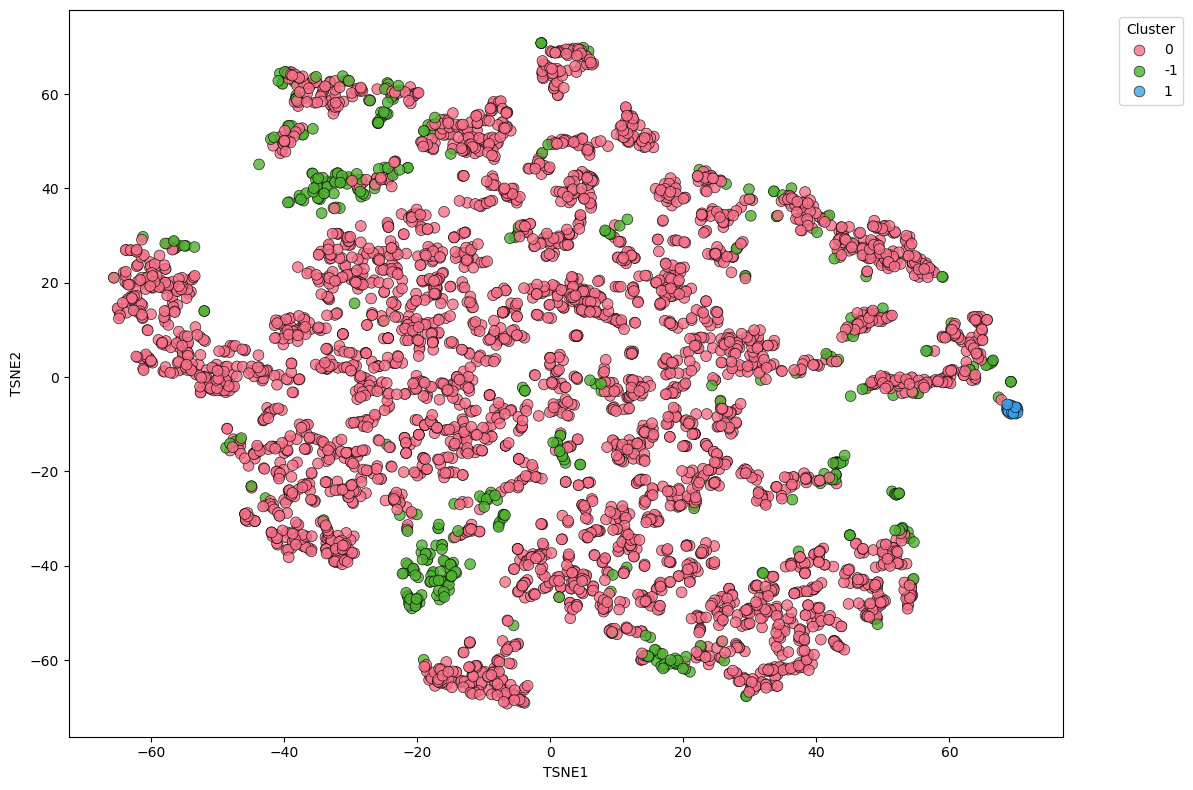

In [14]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Initialize t-SNE
# We use the same df_pca from your clustering script
tsne = TSNE(
    n_components=2, 
    perplexity=30, 
    random_state=0, 
    init='pca', 
    learning_rate='auto'
)

# 2. Fit and transform
print("Running t-SNE... this may take a moment.")
tsne_results = tsne.fit_transform(df_pca)

# 3. Prepare plotting DataFrame
df_tsne_agg = pd.DataFrame(tsne_results, columns=['TSNE1', 'TSNE2'])
# We use 'best_labels' generated at the end of your provided script
df_tsne_agg['Cluster'] = labels.astype(str) 

# 4. Visualization with High Contrast
plt.figure(figsize=(12, 8))

# Using 'husl' palette provides evenly spaced, highly saturated colors 
# which is better for high cluster counts (n up to 30)
num_clusters = len(df_tsne_agg['Cluster'].unique())
palette = sns.color_palette("husl", num_clusters)

sns.scatterplot(
    x='TSNE1', 
    y='TSNE2',
    hue='Cluster',
    data=df_tsne_agg,
    palette=palette, 
    s=60,
    alpha=0.8,
    edgecolor='black',
    linewidth=0.5
)

plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2 if num_clusters > 15 else 1)
plt.tight_layout()
plt.show()

# Agglomerative Clustering

Starting Agglomerative Grid Search...

Top 10 Agglomerative Configurations (Sorted by V-Measure):
   n_clusters   linkage  homogeneity  completeness  v_measure
0           2      ward     0.045129      0.065291   0.053369
2           2   average     0.000095      0.007995   0.000188
3           2    single     0.000095      0.007995   0.000188
1           2  complete     0.000019      0.000252   0.000035

Best Parameters: n_clusters=2, linkage='ward'
V-Measure: 0.0534

Visualizing best model...
Silhouette Score: 0.37825343012809753


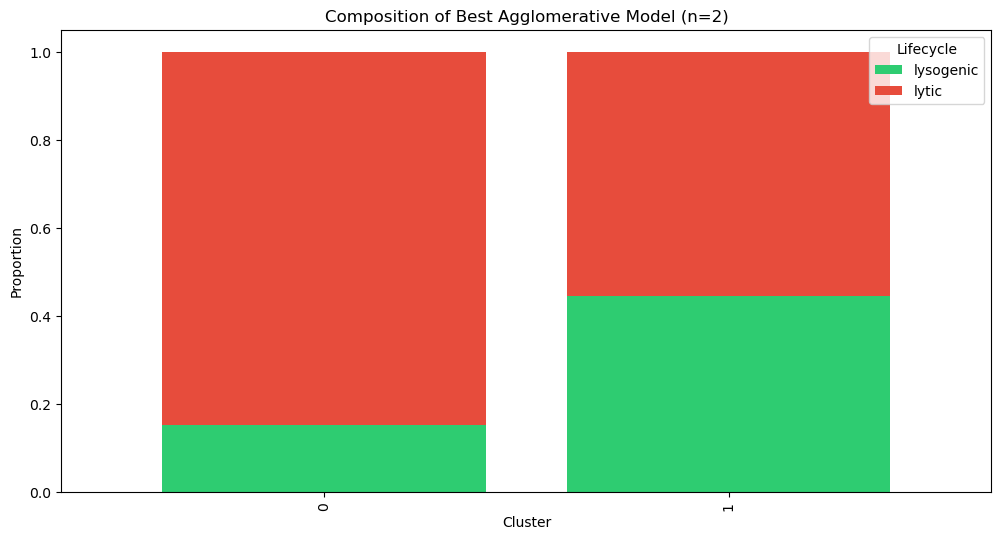

In [15]:
from sklearn.metrics import homogeneity_score, completeness_score, v_measure_score
from sklearn.metrics import silhouette_score

# --- GRID SEARCH FOR AGGLOMERATIVE CLUSTERING ---

# We want to test a range of cluster counts 
# n_clusters_values = range(2, 30, 1)  
n_clusters_values = range(2, 3, 1)
linkage_values = ['ward', 'complete', 'average', 'single']

results = []
print("Starting Agglomerative Grid Search...")

for linkage in linkage_values:
    for n_k in n_clusters_values:
        
        if linkage == 'ward':
            metric = 'euclidean'
        else:
            metric = 'euclidean' 
        
        # A. Run Agglomerative Clustering
        agg = AgglomerativeClustering(n_clusters=n_k, linkage=linkage, metric=metric)
        labels = agg.fit_predict(df_pca)
        
        # B. Calculate Scores
        # V-Measure balances Homogeneity (purity) and Completeness (grouping)
        h_score = homogeneity_score(aligned_lifecycles, labels)
        c_score = completeness_score(aligned_lifecycles, labels)
        v_score = v_measure_score(aligned_lifecycles, labels)
        
        results.append({
            'n_clusters': n_k, 
            'linkage': linkage, 
            'metric': metric,
            'homogeneity': h_score,
            'completeness': c_score,
            'v_measure': v_score # <--- Look at this to pick the best trade-off
        })

# --- RESULTS ---
df_results_agg = pd.DataFrame(results)

if not df_results_agg.empty:
    # Sort by V-Measure (Balanced Score) instead of just Homogeneity
    df_results_agg = df_results_agg.sort_values(by='v_measure', ascending=False)
    
    print("\nTop 10 Agglomerative Configurations (Sorted by V-Measure):")
    print(df_results_agg.head(10)[['n_clusters', 'linkage', 'homogeneity', 'completeness', 'v_measure']])
    
    best_row = df_results_agg.iloc[0]
    print(f"\nBest Parameters: n_clusters={best_row['n_clusters']}, linkage='{best_row['linkage']}'")
    print(f"V-Measure: {best_row['v_measure']:.4f}")
    
    # --- VISUALIZE THE BEST MODEL ---
    print("\nVisualizing best model...")
    best_model = AgglomerativeClustering(
        n_clusters=int(best_row['n_clusters']), 
        linkage=best_row['linkage'], 
        metric=best_row['metric']
    )
    best_labels = best_model.fit_predict(df_pca)
    print(f"Silhouette Score: {silhouette_score(df_pca, best_labels)}")
    
    # Create the counts dataframe for plotting
    df_plot = pd.DataFrame({'Cluster': best_labels, 'Lifecycle': aligned_lifecycles})
    
    # Calculate ratios
    cross_tab = pd.crosstab(df_plot['Cluster'], df_plot['Lifecycle'], normalize='index')
    
    # Plot
    cross_tab.plot(
        kind='bar', 
        stacked=True, 
        figsize=(12, 6), 
        color=['#2ecc71', '#e74c3c'], # Adjust colors if needed (Green=Lysogenic, Red=Lytic)
        width=0.8
    )
    
      
    
    plt.title(f"Composition of Best Agglomerative Model (n={best_row['n_clusters']})")
    plt.ylabel("Proportion")
    plt.show()

else:
    print("No results generated.")

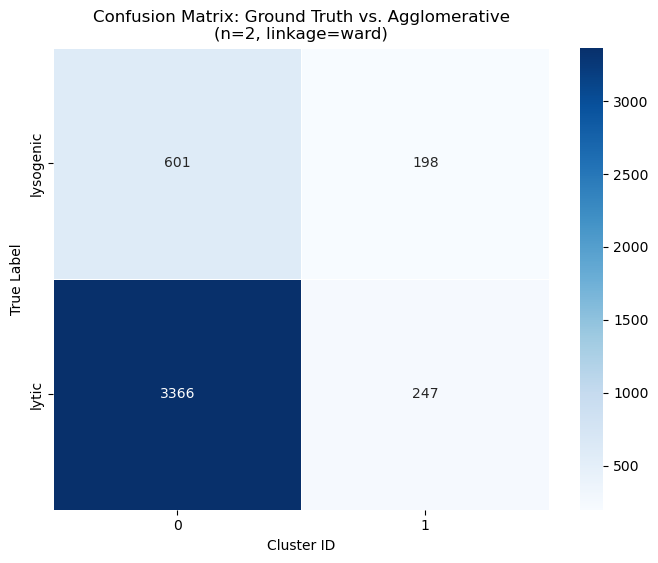

In [16]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Retrieve best parameters
# Assuming 'results_agg_df' is your DataFrame from the agglomerative search
best_row = df_results_agg.iloc[0]

# Access parameters by column name to be safe
best_n_clusters = int(best_row['n_clusters']) 
best_linkage = best_row['linkage']

# 2. Initialize and Fit Agglomerative Clustering
# Note: AgglomerativeClustering implies Euclidean distance by default unless 'metric' is specified
agg_model = AgglomerativeClustering(
    n_clusters=best_n_clusters,
    linkage=best_linkage
)

cluster_labels_agg = agg_model.fit_predict(df_pca)

# 3. Create the Confusion Matrix (Contingency Table)
conf_matrix_agg = pd.crosstab(
    aligned_lifecycles,       # Rows: True Classes
    cluster_labels_agg,       # Cols: Predicted Clusters
    rownames=['True Label'], 
    colnames=['Cluster ID']
)

# 4. Plot as a Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_agg, annot=True, fmt='d', cmap='Blues', linewidths=.5)
plt.title(f'Confusion Matrix: Ground Truth vs. Agglomerative\n(n={best_n_clusters}, linkage={best_linkage})')
plt.show()

Running t-SNE... this may take a moment.


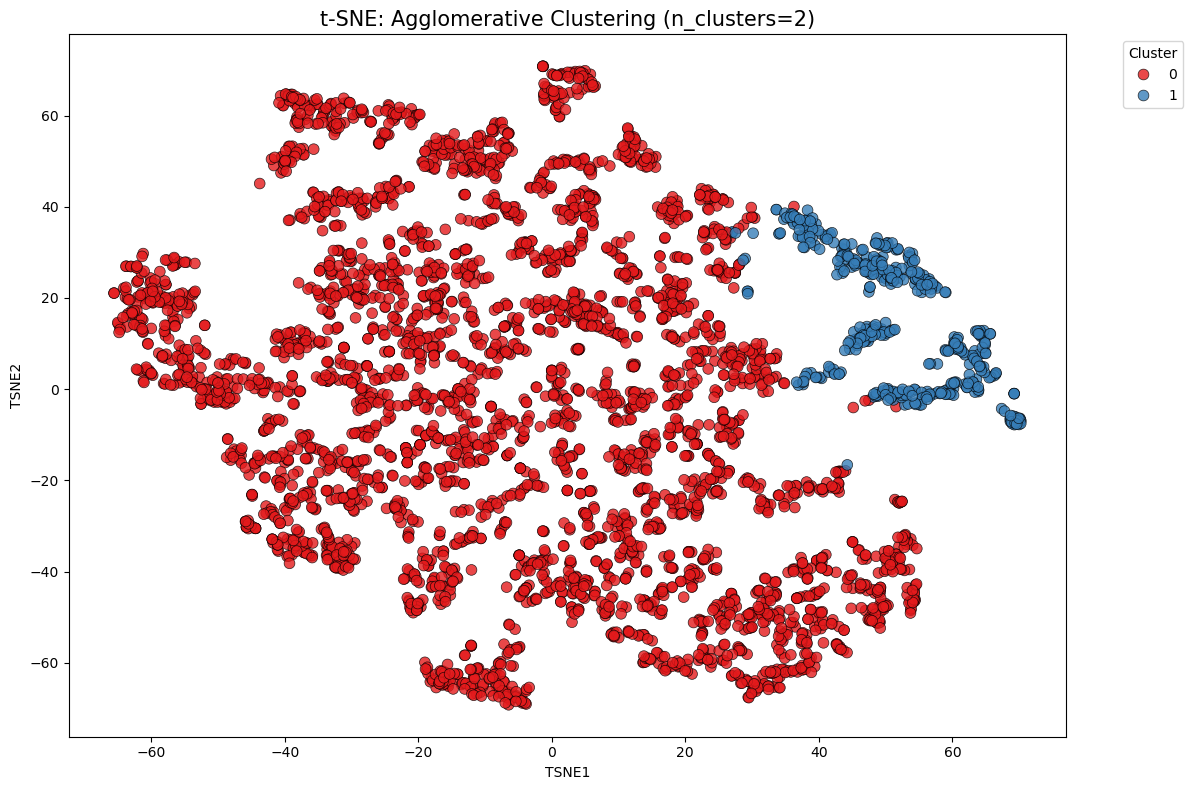

In [17]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Initialize t-SNE
# We use the same df_pca from your clustering script
tsne = TSNE(
    n_components=2, 
    perplexity=30, 
    random_state=0, 
    init='pca', 
    learning_rate='auto'
)

# 2. Fit and transform
print("Running t-SNE... this may take a moment.")
tsne_results = tsne.fit_transform(df_pca)

# 3. Prepare plotting DataFrame
df_tsne_agg = pd.DataFrame(tsne_results, columns=['TSNE1', 'TSNE2'])
# We use 'best_labels' generated at the end of your provided script
df_tsne_agg['Cluster'] = best_labels.astype(str) 

# 4. Visualization with High Contrast
plt.figure(figsize=(12, 8))

# Using 'husl' palette provides evenly spaced, highly saturated colors 
# which is better for high cluster counts (n up to 30)
num_clusters = len(df_tsne_agg['Cluster'].unique())
palette = sns.color_palette("husl", num_clusters)

sns.scatterplot(
    x='TSNE1', 
    y='TSNE2',
    hue='Cluster',
    data=df_tsne_agg,
    palette="Set1", 
    s=60,
    alpha=0.8,
    edgecolor='black',
    linewidth=0.5
)

plt.title(f"t-SNE: Agglomerative Clustering (n_clusters={best_row['n_clusters']})", fontsize=15)
plt.legend(title='Cluster', bbox_to_anchor=(1.05, 1), loc='upper left', ncol=2 if num_clusters > 15 else 1)
plt.tight_layout()
plt.show()

### K-Means

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score, 
    homogeneity_score, 
    completeness_score, 
    v_measure_score
)
from itertools import product
import pandas as pd

RANDOM_STATE = 0

# Parameter grid (k is fixed at 2)
param_grid = {
    "init": ["k-means++", "random"],
    "n_init": [10, 20, 50],
    "max_iter": [300, 500, 1000]
}

results = []

for init, n_init, max_iter in product(
    param_grid["init"],
    param_grid["n_init"],
    param_grid["max_iter"]
):
    kmeans = KMeans(
        n_clusters=2,
        init=init,
        n_init=n_init,
        max_iter=max_iter,
        random_state=RANDOM_STATE
    )
    
    labels = kmeans.fit_predict(df_pca)
    
    # Calculate Internal Metric (Geometry)
    sil_score = silhouette_score(df_pca, labels)
    
    # Calculate External Metrics (Ground Truth Agreement)
    # REPLACE 'aligned_lifecycles' with your actual ground truth variable if different
    h_score = homogeneity_score(aligned_lifecycles, labels)
    c_score = completeness_score(aligned_lifecycles, labels)
    v_score = v_measure_score(aligned_lifecycles, labels)
    
    results.append({
        "init": init,
        "n_init": n_init,
        "max_iter": max_iter,
        "silhouette_score": sil_score,
        "homogeneity": h_score,
        "completeness": c_score,
        "v_measure": v_score
    })

# Convert to DataFrame
# You can now sort by 'v_measure' to see which config best matches your labels,
# or 'silhouette_score' to see which is most geometrically distinct.
results_df = pd.DataFrame(results).sort_values(
    by="v_measure", ascending=False
)

results_df.head()

,init,n_init,max_iter,silhouette_score,homogeneity,completeness,v_measure
3,k-means++,20,300,0.268194,0.028504,0.019933,0.023461
4,k-means++,20,500,0.268194,0.028504,0.019933,0.023461
5,k-means++,20,1000,0.268194,0.028504,0.019933,0.023461
17,random,50,1000,0.267916,0.028197,0.019709,0.023201
12,random,20,300,0.267916,0.028197,0.019709,0.023201


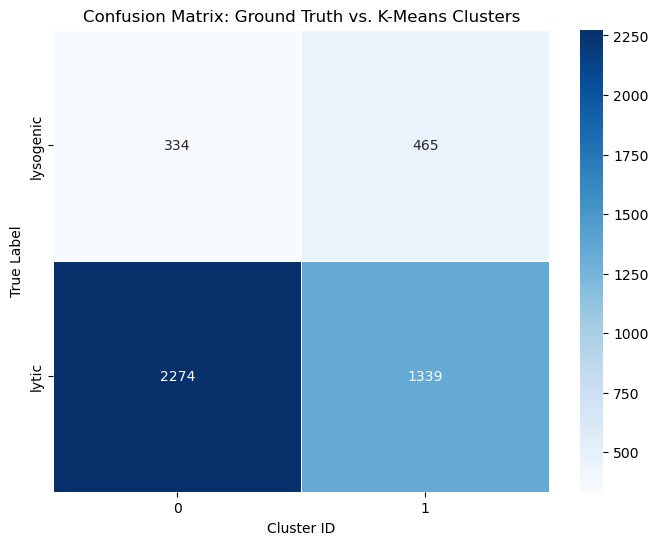

In [19]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

best_param_kmeans = results_df.iloc[0].to_list()

best_kmeans = KMeans(
    n_clusters=2, 
    init=best_param_kmeans[0], 
    n_init=best_param_kmeans[1], 
    max_iter=best_param_kmeans[2], 
    random_state=RANDOM_STATE
)
cluster_labels = best_kmeans.fit_predict(df_pca)

# 2. Create the Confusion Matrix (Contingency Table)
# We use pandas crosstab because it handles string labels in ground truth gracefully
conf_matrix = pd.crosstab(
    aligned_lifecycles,   # Rows: True Classes
    cluster_labels,       # Cols: Predicted Clusters
    rownames=['True Label'], 
    colnames=['Cluster ID']
)

# 3. Plot as a Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', linewidths=.5)
plt.title('Confusion Matrix: Ground Truth vs. K-Means Clusters')
plt.show()

In [20]:
best_params = results_df.iloc[0]

best_kmeans = KMeans(
    n_clusters=2,
    init=best_params["init"],
    n_init=int(best_params["n_init"]),
    max_iter=int(best_params["max_iter"]),
    random_state=RANDOM_STATE
)

cluster_labels = best_kmeans.fit_predict(df_pca)
print("Best Silhouette Score:", results_df.iloc[0]["silhouette_score"])


Best Silhouette Score: 0.2681935727596283


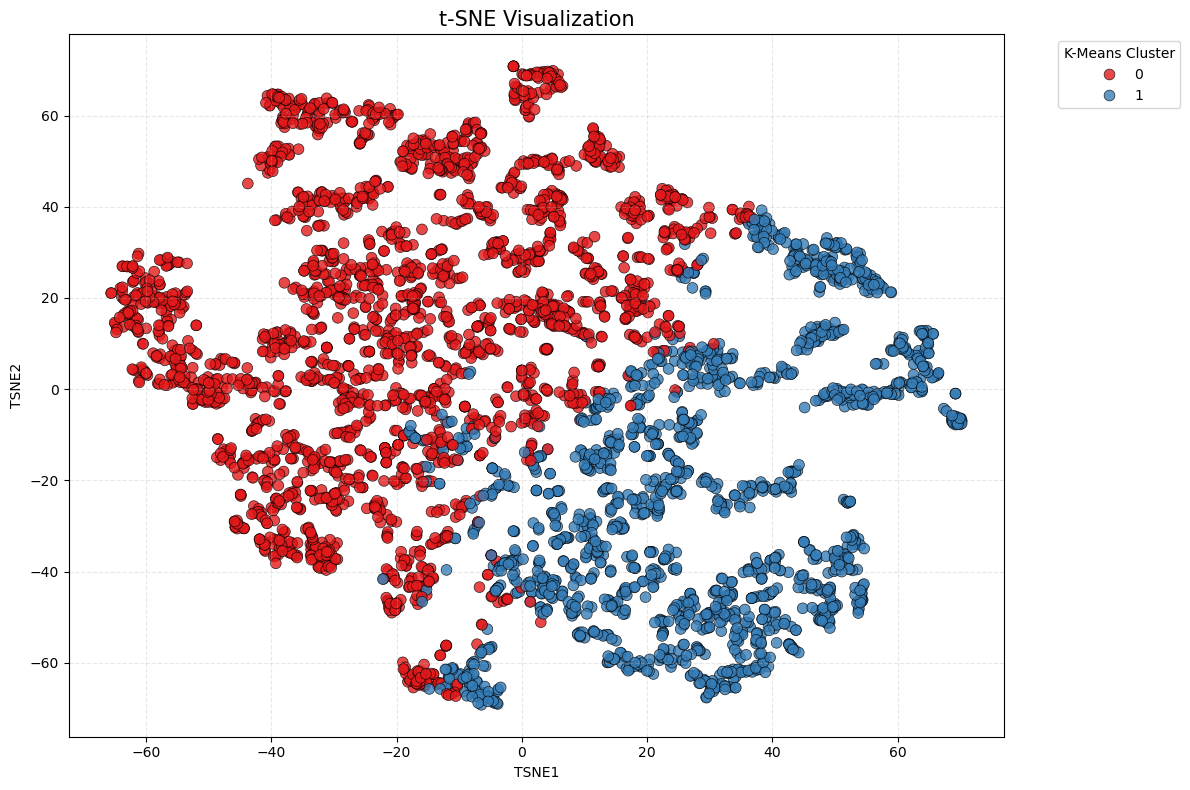

In [21]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Re-run the best model based on your results_df
best_params = results_df.iloc[0]
kmeans_best = KMeans(
    n_clusters=2,
    init=best_params['init'],
    n_init=int(best_params['n_init']),
    max_iter=int(best_params['max_iter']),
    random_state=RANDOM_STATE
)
labels = kmeans_best.fit_predict(df_pca)

# 2. Apply t-SNE to reduce df_pca to 2D
# Perplexity usually ranges from 5 to 50; adjust based on dataset size
tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE)
tsne_results = tsne.fit_transform(df_pca)

# 3. Create a DataFrame for plotting
df_tsne = pd.DataFrame(tsne_results, columns=['TSNE1', 'TSNE2'])
df_tsne['Cluster'] = labels.astype(str) # Convert to string for discrete color palette

# Using a high-contrast palette like 'Set1' or 'bright'
# 'Set1' uses Red and Blue for the first two categories—very high contrast.
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x='TSNE1', 
    y='TSNE2',
    hue='Cluster',
    data=df_tsne,
    palette="Set1",       # High-contrast categorical colors
    s=60,                 # Increased point size
    alpha=0.8,            # Slight transparency to see density
    edgecolor='black',    # Adds a thin border to each point for definition
    linewidth=0.5
)

plt.title('t-SNE Visualization', fontsize=15)
plt.legend(title='K-Means Cluster', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.3) # Subtle grid for scale
plt.tight_layout()

plt.show()

Running t-SNE...


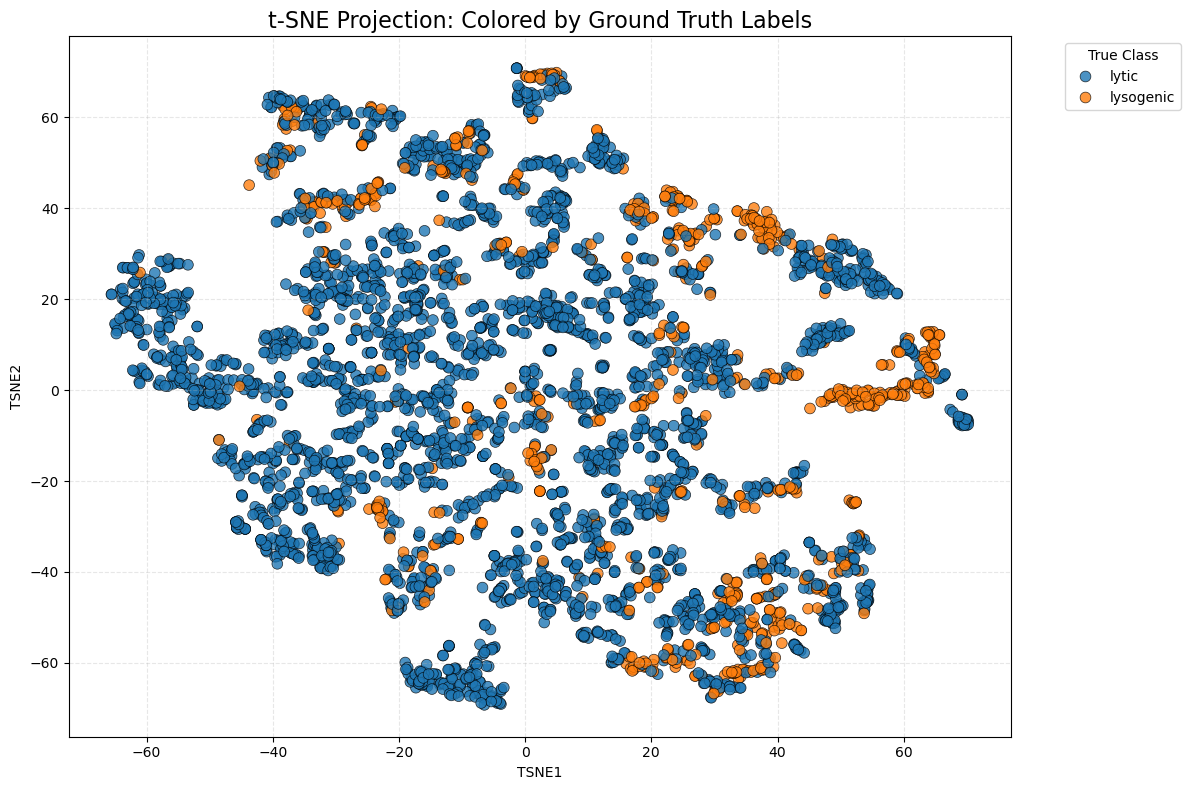

In [22]:
from sklearn.manifold import TSNE
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Run t-SNE on your PCA data
# (If you already have 'df_tsne' from previous steps, you can skip this part)
print("Running t-SNE...")
tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE, n_jobs=-1)
tsne_results = tsne.fit_transform(df_pca)

# 2. Create a DataFrame specifically for this plot
df_plot = pd.DataFrame(tsne_results, columns=['TSNE1', 'TSNE2'])
df_plot['True Label'] = aligned_lifecycles  # Assign your ground truth labels here

# 3. Generate the Plot
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x='TSNE1', 
    y='TSNE2', 
    hue='True Label',     # Color points by their ACTUAL class
    data=df_plot,
    palette='tab10',      # Distinct colors for categories
    s=60,                 # Increased point size
    alpha=0.8,            # Slight transparency to see density
    edgecolor='black',    # Adds a thin border to each point for definition
    linewidth=0.5
)

plt.title('t-SNE Projection: Colored by Ground Truth Labels', fontsize=16)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='True Class')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Running UMAP...


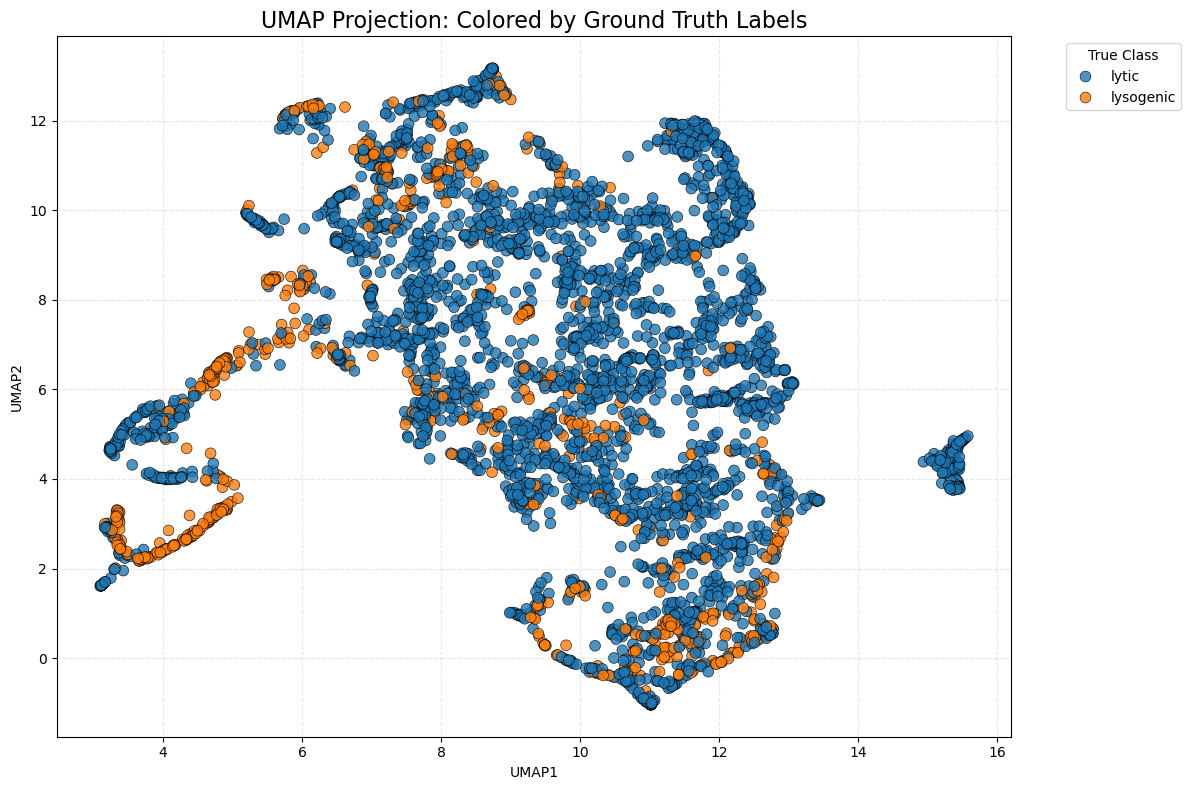

In [23]:
import umap
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# 1. Esecuzione di UMAP sui dati PCA
print("Running UMAP...")
# n_neighbors e min_dist sono i parametri principali per bilanciare struttura locale e globale
reducer = umap.UMAP(
    n_neighbors=15, 
    min_dist=0.1, 
    n_components=2
)
umap_results = reducer.fit_transform(df_pca)

# 2. Creazione del DataFrame per il plot
df_plot_umap = pd.DataFrame(umap_results, columns=['UMAP1', 'UMAP2'])
df_plot_umap['True Label'] = aligned_lifecycles

# 3. Generazione del Grafico
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x='UMAP1', 
    y='UMAP2', 
    hue='True Label',
    data=df_plot_umap,
    palette='tab10',
    s=60,
    alpha=0.8,
    edgecolor='black',
    linewidth=0.5
)

plt.title('UMAP Projection: Colored by Ground Truth Labels', fontsize=16)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title='True Class')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()